# 03 -- Fine-tuning Timestral-5M

Full fine-tuning of Timestral-5M on the exact task notebook 02 scored zero-shot: context = the last 1024 values of `y = target_30d(GK daily variance)`, forecast 30 steps, read step 30 (`y[t+30] = log realized_var at t`). Then it is scored on **the same test set** (2022+, every 5th trading day, 10 tickers) against GARCH, HAR and zero-shot Timestral.

- **Train**: every origin whose 30 target days end by 2018-12-31. **Validation**: origins in 2019-2021 whose targets end by 2021-12-31 (every 5th day, as in the test set). The test period (2022+) is never touched before section 5.
- **Loss**: pinball loss over the model's 21 quantile levels and the 30 steps, in log space.
- **No symmetric averaging**: training runs one forward pass per window, so the fine-tuned model is evaluated the same way. Its zero-shot reference is `ts5m_mean_nosym` from notebook 02, not `ts5m_mean`.

Needs a GPU runtime with `torch` + `timestral` (run notebooks 01 and 02 first; this one reads their CSVs).

In [2]:
import os
import sys

try:
    import google.colab  # noqa: F401
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/timestral-vol-data"
    os.makedirs(f"{DATA}/results", exist_ok=True)
    os.makedirs(f"{DATA}/checkpoints", exist_ok=True)
    os.environ["HF_HOME"] = f"{DATA}/hf_cache"

    REPO_DIR = "/content/timestral-vol"
    REPO_URL = "https://github.com/MachaGotJuice/timestral-vol.git"
    if os.path.isdir(REPO_DIR):
        os.chdir(REPO_DIR)
        !git pull
    else:
        !git clone {REPO_URL} {REPO_DIR}
        os.chdir(REPO_DIR)
    sys.path.insert(0, REPO_DIR)
    !pip install -q -r requirements.txt

    try:
        from google.colab import userdata
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception:
        pass
else:
    DATA = None

Mounted at /content/drive
Cloning into '/content/timestral-vol'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 69 (delta 31), reused 62 (delta 24), pack-reused 0 (from 0)
Receiving objects: 100% (69/69), 713.26 KiB | 17.83 MiB/s, done.
Resolving deltas: 100% (31/31), done.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.data import DEFAULT_START, DEFAULT_TICKERS, download_ohlc, forecast_origins, garman_klass, realized_forward, target_30d
from src.evaluation import calibration_table, dm_table, load_forecasts, qlike_tables
from src.finetune import CONTEXT_LEN, HORIZON, TEST_START, build_datasets, pinball_loss, point_forecasts, train
from src.metrics import qlike
from src.timestral_utils import forecast_quantiles, load_finetuned, load_model

plt.rcParams["figure.figsize"] = (12, 4)

STEP = 5
LRS = [1e-5, 3e-5]
MAX_STEPS = int(os.environ.get("FT_MAX_STEPS", 3000))
EVAL_EVERY = 250
BATCH_SIZE = 32
PATIENCE = 4  # stop a run after 4 evaluations (1,000 steps) without a new best validation QLIKE

RESULTS = f"{DATA}/results" if DATA else "results"
CKPT_ROOT = os.environ.get("FT_CKPT_ROOT", f"{DATA}/checkpoints/ts5m_ft" if DATA else "checkpoints/ts5m_ft")
os.makedirs(RESULTS, exist_ok=True)
os.makedirs(CKPT_ROOT, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| checkpoints:", CKPT_ROOT, "| max steps:", MAX_STEPS)

device: cpu | checkpoints: /content/drive/MyDrive/timestral-vol-data/checkpoints/ts5m_ft | max steps: 3000


## 1. Training and validation windows

One window per origin `s`: context `y[s-1023 .. s]`, targets `y[s+1 .. s+30]`. `src.finetune.build_datasets` asserts that no training target falls after 2018-12-31 and no validation target after 2021-12-31, and that `y[s+30] = log(realized_var at s)` for every window.

In [4]:
daily_vars = {t: garman_klass(download_ohlc(t, start=DEFAULT_START, cache_dir="cache")) for t in DEFAULT_TICKERS}
train_set, val_set = build_datasets(daily_vars, val_step=STEP)

for name, ws in [("train", train_set), ("val", val_set)]:
    print(f"{name:5s} {len(ws):6d} windows | origins {ws.origin_dates.min().date()} .. {ws.origin_dates.max().date()}"
          f" | last target date {ws.target_end_dates.max().date()}")
pd.Series(train_set.tickers).value_counts().sort_index().to_frame("train windows").T

train  24410 windows | origins 2009-03-10 .. 2018-11-14 | last target date 2018-12-31
val     1460 windows | origins 2019-01-02 .. 2021-11-16 | last target date 2021-12-30


,AAPL,EFA,GLD,IWM,JPM,MSFT,QQQ,SPY,TLT,XOM
train windows,2441,2441,2441,2441,2441,2441,2441,2441,2441,2441


## 2. Differentiable forecasts: the three checks

`src.timestral_utils.differentiable_quantiles` calls Timestral's internal `_forecast_raw` under `torch.enable_grad()` (the public `forecast()` runs in inference mode). `tests/test_differentiable.py` checks that (a) without any parameter change it equals `forecast(..., symmetric_averaging=False, clip_nonnegative=False)` within 1e-5, (b) gradients reach the model's parameters, and (c) a 16-window batch can be overfit in 200 steps.

In [5]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-m", "torch", "tests/test_differentiable.py"],
                        capture_output=True, text=True)
print(result.stdout[-1500:])
assert result.returncode == 0, result.stderr[-3000:]

...                                                                      [100%]
3 passed in 110.90s (0:01:50)



## 3. Zero-shot reference on the validation set

Timestral-5M, untouched, through the public `forecast(..., symmetric_averaging=False)`. Training logs its step-0 validation metrics through the differentiable path; the two must agree, which checks that the training loop starts from exactly the zero-shot model.

In [6]:
zs_model = load_model("5M", device=DEVICE)
zs_q, levels = forecast_quantiles(zs_model, val_set.contexts, horizon=HORIZON, symmetric_averaging=False)
zs_val = {
    "pinball": float(pinball_loss(torch.as_tensor(zs_q), torch.as_tensor(val_set.targets), levels)),
    "qlike": qlike(val_set.realized_var, point_forecasts(zs_q, levels)["mean"]),
}
print(f"zero-shot (no symmetric averaging) on validation: pinball {zs_val['pinball']:.5f}, QLIKE {zs_val['qlike']:.5f}")
del zs_model

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

zero-shot (no symmetric averaging) on validation: pinball 0.10673, QLIKE 0.60192


## 4. Training

Full fine-tuning, AdamW (weight decay 0), batch 32, gradient clipping at 1.0, fp16 autocast on GPU. Two learning rates, `1e-5` and `3e-5`, each in its own checkpoint folder. Every 250 steps: validation pinball loss and validation QLIKE (step-30 mean forecast, as in notebook 02); `best.pt` keeps the weights with the best validation QLIKE. Rerunning this cell resumes each run from its `last.pt` (finished runs are skipped).

The run used on the test set is the one with the lowest best-validation QLIKE -- chosen on validation only.

In [7]:
runs = {}
for lr in LRS:
    ckpt_dir = os.path.join(CKPT_ROOT, f"lr{lr:g}")
    print(f"=== lr {lr:g} -> {ckpt_dir}")
    torch.manual_seed(0)
    forecaster = load_model("5M", device=DEVICE)
    runs[lr] = train(forecaster, train_set, val_set, ckpt_dir, lr=lr, max_steps=MAX_STEPS, batch_size=BATCH_SIZE,
                     eval_every=EVAL_EVERY, grad_clip=1.0, amp=True, patience=PATIENCE, seed=0)
    del forecaster

=== lr 1e-05 -> /content/drive/MyDrive/timestral-vol-data/checkpoints/ts5m_ft/lr1e-05


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

step     0 | train pinball nan | val pinball 0.10673 | val QLIKE 0.60192 *
step   250 | train pinball 0.08105 | val pinball 0.10551 | val QLIKE 0.55385 *
        4.0 min elapsed this session
step   500 | train pinball 0.07541 | val pinball 0.10656 | val QLIKE 0.56867
        7.9 min elapsed this session
step   750 | train pinball 0.07438 | val pinball 0.10714 | val QLIKE 0.56921
        11.8 min elapsed this session
step  1000 | train pinball 0.07195 | val pinball 0.10828 | val QLIKE 0.58497
        15.7 min elapsed this session
step  1250 | train pinball 0.07143 | val pinball 0.10895 | val QLIKE 0.61144
        19.5 min elapsed this session
early stop: no val QLIKE improvement in 4 evaluations
=== lr 3e-05 -> /content/drive/MyDrive/timestral-vol-data/checkpoints/ts5m_ft/lr3e-05


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

step     0 | train pinball nan | val pinball 0.10673 | val QLIKE 0.60192 *
step   250 | train pinball 0.07794 | val pinball 0.10637 | val QLIKE 0.55260 *
        3.8 min elapsed this session
step   500 | train pinball 0.06954 | val pinball 0.11119 | val QLIKE 0.60528
        7.6 min elapsed this session
step   750 | train pinball 0.06308 | val pinball 0.11674 | val QLIKE 0.71641
        11.4 min elapsed this session
step  1000 | train pinball 0.05615 | val pinball 0.12092 | val QLIKE 0.74241
        15.3 min elapsed this session
step  1250 | train pinball 0.05226 | val pinball 0.12242 | val QLIKE 0.82005
        19.1 min elapsed this session
early stop: no val QLIKE improvement in 4 evaluations


In [8]:
for lr, state in runs.items():
    step0 = state["evals"][0]
    assert step0["step"] == 0
    np.testing.assert_allclose(step0["val_qlike"], zs_val["qlike"], rtol=1e-4)
    np.testing.assert_allclose(step0["val_pinball"], zs_val["pinball"], rtol=1e-4)
print("step-0 validation metrics match the zero-shot (no symmetric averaging) model for every run.")

summary = pd.DataFrame([
    {"lr": lr, "steps_run": s["step"], "best_step": s["best_step"], "best_val_qlike": s["best_qlike"],
     "zero_shot_val_qlike": s["evals"][0]["val_qlike"], "skipped_steps": s["skipped_steps"]}
    for lr, s in runs.items()
]).set_index("lr")
BEST_LR = summary["best_val_qlike"].idxmin()
BEST_CKPT = os.path.join(CKPT_ROOT, f"lr{BEST_LR:g}", "best.pt")
print("selected:", BEST_LR, BEST_CKPT)
summary.round(5)

step-0 validation metrics match the zero-shot (no symmetric averaging) model for every run.
selected: 3e-05 /content/drive/MyDrive/timestral-vol-data/checkpoints/ts5m_ft/lr3e-05/best.pt


,steps_run,best_step,best_val_qlike,zero_shot_val_qlike,skipped_steps
lr,,,,,
0.00001,1250,250,0.55385,0.60192,0
0.00003,1250,250,0.55260,0.60192,0


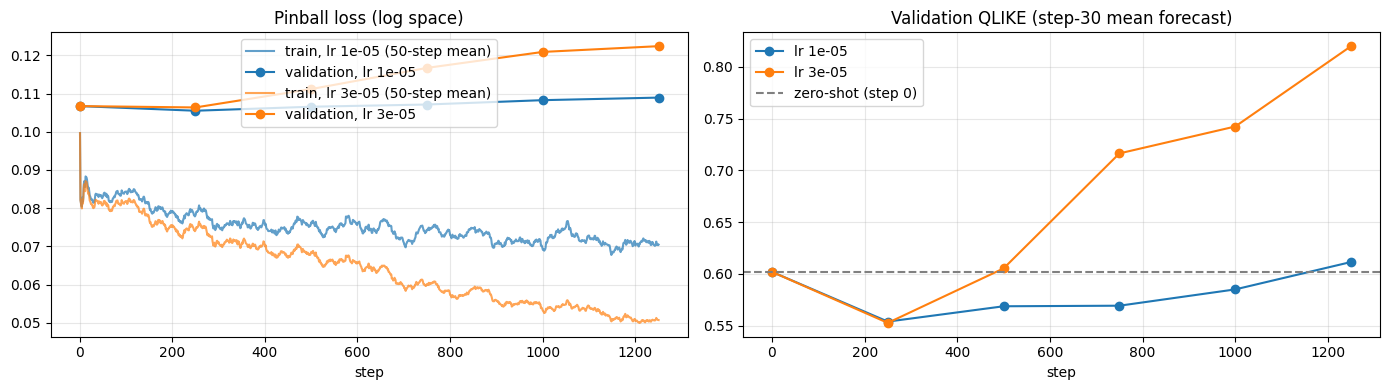

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for lr, state in runs.items():
    train_log = pd.DataFrame(state["train"], columns=["step", "loss"]).set_index("step")["loss"]
    evals = pd.DataFrame(state["evals"]).set_index("step")
    line, = axes[0].plot(train_log.rolling(50, min_periods=1).mean(), alpha=0.7, label=f"train, lr {lr:g} (50-step mean)")
    axes[0].plot(evals.index, evals["val_pinball"], "o-", color=line.get_color(), label=f"validation, lr {lr:g}")
    axes[1].plot(evals.index, evals["val_qlike"], "o-", color=line.get_color(), label=f"lr {lr:g}")
axes[1].axhline(zs_val["qlike"], color="grey", ls="--", label="zero-shot (step 0)")
axes[0].set(title="Pinball loss (log space)", xlabel="step")
axes[1].set(title="Validation QLIKE (step-30 mean forecast)", xlabel="step")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Test set

The selected `best.pt`, forecasting the test origins exactly as notebook 02 did (same origins, same 1024-value contexts, step 30, `quantile_mean` of the exponentiated quantiles), with `symmetric_averaging=False`. Models `ts5m_ft_mean` and `ts5m_ft_median`.

In [10]:
ft_model = load_finetuned(BEST_CKPT, device=DEVICE)

records = []
for ticker in DEFAULT_TICKERS:
    daily_var = daily_vars[ticker]
    y = target_30d(daily_var, window=30)
    origins = forecast_origins(daily_var.index, TEST_START, horizon=HORIZON, step=STEP)
    assert origins.min() >= TEST_START
    realized = np.array([realized_forward(daily_var, t, horizon=HORIZON) for t in origins])
    contexts = np.stack([y.loc[:t].iloc[-CONTEXT_LEN:].values for t in origins])

    quantiles, levels = forecast_quantiles(ft_model, contexts, horizon=HORIZON, symmetric_averaging=False)
    pf = point_forecasts(quantiles, levels)
    for name in ["median", "mean"]:
        for i, t in enumerate(origins):
            records.append({"ticker": ticker, "origin_date": t, "model": f"ts5m_ft_{name}",
                            "forecast_var": float(pf[name][i]), "realized_var": float(realized[i]),
                            "q10": float(pf["q10"][i]), "q90": float(pf["q90"][i])})

ft_results = pd.DataFrame(records)
ft_results.to_csv(f"{RESULTS}/forecasts_timestral_finetuned.csv", index=False)
os.makedirs("results", exist_ok=True)
ft_results.to_csv("results/forecasts_timestral_finetuned.csv", index=False)
ft_results.shape

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

(4760, 7)

In [12]:
full = load_forecasts(f"{RESULTS}/forecasts_baselines.csv", f"{RESULTS}/forecasts_timestral_zeroshot.csv",
                      f"{RESULTS}/forecasts_timestral_finetuned.csv")  # asserts realized_var is identical across files
full.to_csv(f"{RESULTS}/forecasts_all.csv", index=False)

FINAL = ["garch", "har", "ts5m_mean_nosym", "ts5m_ft_mean", "ts209m_mean"]
pooled, per_ticker, per_year = qlike_tables(full, FINAL)
final_table = pd.concat([pooled, calibration_table(full, FINAL)], axis=1)
final_table.round(4)

,qlike,log_bias,coverage_10_90
model,,,
garch,0.1507,0.1188,NaN
har,0.1160,0.1553,NaN
ts5m_mean_nosym,0.1441,0.1298,0.7773
ts5m_ft_mean,0.1480,0.0647,0.7782
ts209m_mean,0.1423,0.1809,0.7857


In [13]:
per_ticker.round(4)

model,garch,har,ts5m_mean_nosym,ts5m_ft_mean,ts209m_mean
ticker,,,,,
SPY,0.2183,0.1826,0.2420,0.2290,0.2277
QQQ,0.1631,0.1326,0.1668,0.1700,0.1638
IWM,0.1397,0.1168,0.1480,0.1416,0.1493
EFA,0.2132,0.1562,0.1931,0.2017,0.1923
TLT,0.0837,0.0720,0.0714,0.0752,0.0790
GLD,0.2353,0.1740,0.2293,0.2483,0.2188
AAPL,0.1317,0.1006,0.1176,0.1221,0.1150
MSFT,0.1240,0.0762,0.0977,0.0994,0.0971
JPM,0.0985,0.0886,0.1032,0.1148,0.1008


In [14]:
per_year.round(4)

model,garch,har,ts5m_mean_nosym,ts5m_ft_mean,ts209m_mean
year,,,,,
2022,0.1170,0.0822,0.1010,0.1311,0.0962
2023,0.1022,0.0832,0.0819,0.0905,0.0947
2024,0.0836,0.0880,0.0852,0.0788,0.0838
2025,0.3041,0.2055,0.2856,0.2840,0.2772
2026,0.1461,0.1237,0.1759,0.1585,0.1670


Diebold-Mariano on QLIKE losses (`lag=5`), per ticker and pooled (average loss across the 10 tickers per origin date). `mean_diff < 0` means the fine-tuned model has the lower loss.

In [15]:
dm_ft = {ref: dm_table(full, "ts5m_ft_mean", ref, lag=5) for ref in ["har", "ts5m_mean_nosym", "garch"]}
pd.concat({f"vs {ref}": t[["mean_diff", "p_value"]] for ref, t in dm_ft.items()}, axis=1).round(4)

vs har         vs ts5m_mean_nosym          vs garch        
       mean_diff p_value          mean_diff p_value mean_diff p_value
ticker                                                               
SPY       0.0465  0.1820            -0.0129  0.4427    0.0107  0.6150
QQQ       0.0374  0.0270             0.0032  0.8361    0.0070  0.7006
IWM       0.0248  0.1251            -0.0064  0.6237    0.0019  0.8551
EFA       0.0455  0.1185             0.0086  0.6085   -0.0115  0.5161
TLT       0.0032  0.6482             0.0038  0.6237   -0.0085  0.2698
GLD       0.0743  0.1310             0.0190  0.5932    0.0130  0.5727
AAPL      0.0214  0.1649             0.0044  0.7090   -0.0096  0.4254
MSFT      0.0232  0.0033             0.0018  0.8185   -0.0245  0.0755
JPM       0.0262  0.0980             0.0116  0.2771    0.0163  0.2059
XOM       0.0172  0.0050             0.0056  0.4052   -0.0224  0.0691
pooled    0.0320  0.0199             0.0039  0.6652   -0.0027  0.6785

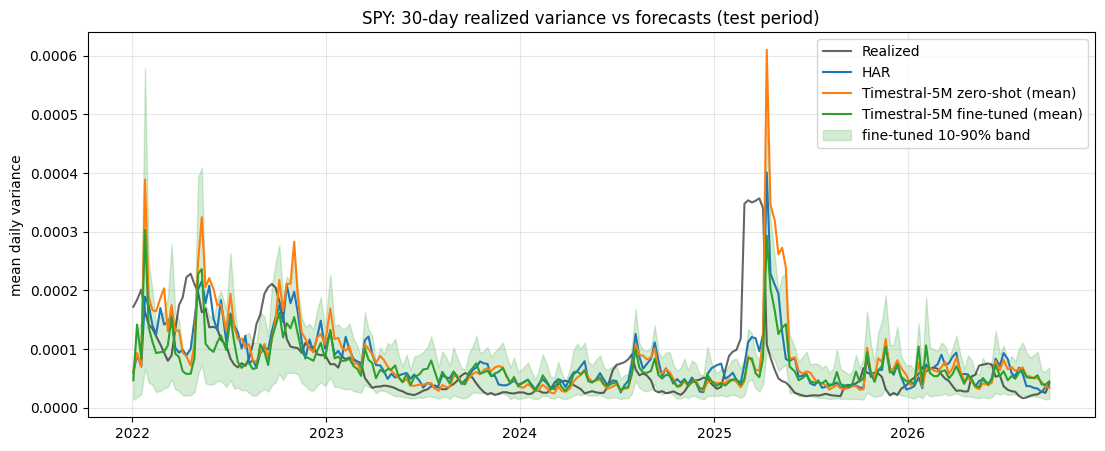

In [16]:
spy = {m: full[(full.ticker == "SPY") & (full.model == m)].sort_values("origin_date") for m in ["har", "ts5m_mean_nosym", "ts5m_ft_mean"]}

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(spy["har"].origin_date, spy["har"].realized_var, color="black", alpha=0.6, label="Realized")
ax.plot(spy["har"].origin_date, spy["har"].forecast_var, label="HAR")
ax.plot(spy["ts5m_mean_nosym"].origin_date, spy["ts5m_mean_nosym"].forecast_var, label="Timestral-5M zero-shot (mean)")
ax.plot(spy["ts5m_ft_mean"].origin_date, spy["ts5m_ft_mean"].forecast_var, label="Timestral-5M fine-tuned (mean)")
ax.fill_between(spy["ts5m_ft_mean"].origin_date, spy["ts5m_ft_mean"].q10, spy["ts5m_ft_mean"].q90,
                alpha=0.2, color="tab:green", label="fine-tuned 10-90% band")
ax.set(title="SPY: 30-day realized variance vs forecasts (test period)", ylabel="mean daily variance")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 6. Conclusion

_Filled in after running the notebook._